# ***Importing Libraries***

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

SEED = 42
keras.utils.set_random_seed(SEED)

# ***Exploratory Data Analysis (EDA)***

In [2]:
!curl -L -O https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip
!unzip -q kagglecatsanddogs_5340.zip -d data

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  786M  100  786M    0     0  49.9M      0  0:00:15  0:00:15 --:--:-- 62.2M


In [3]:
base_dir = "data/PetImages"

print('Cat', len(os.listdir(base_dir + '/Cat')))
print('Dog', len(os.listdir(base_dir + '/Dog')))

Cat 12501
Dog 12501


In [4]:
def load_images(folder, n):
    images = []
    for name in sorted(os.listdir(folder)):
        if len(images) == n:
            break
        try:
            img = Image.open(os.path.join(folder, name)).convert('RGB').resize((128, 128))
            images.append(np.array(img))
        except Exception:
            continue
    return np.array(images, dtype='uint8')

X_cat = load_images(base_dir + '/Cat', 1500)
X_dog = load_images(base_dir + '/Dog', 1500)

In [5]:
X = np.concatenate([X_cat, X_dog])
y = np.array([0] * len(X_cat) + [1] * len(X_dog))
class_names = ['Cat', 'Dog']
print(X.shape, y.shape)

(3000, 128, 128, 3) (3000,)


In [6]:
pd.Series(y).map(dict(enumerate(class_names))).value_counts()

,count
Cat,1500
Dog,1500


# ***Data Visualization***

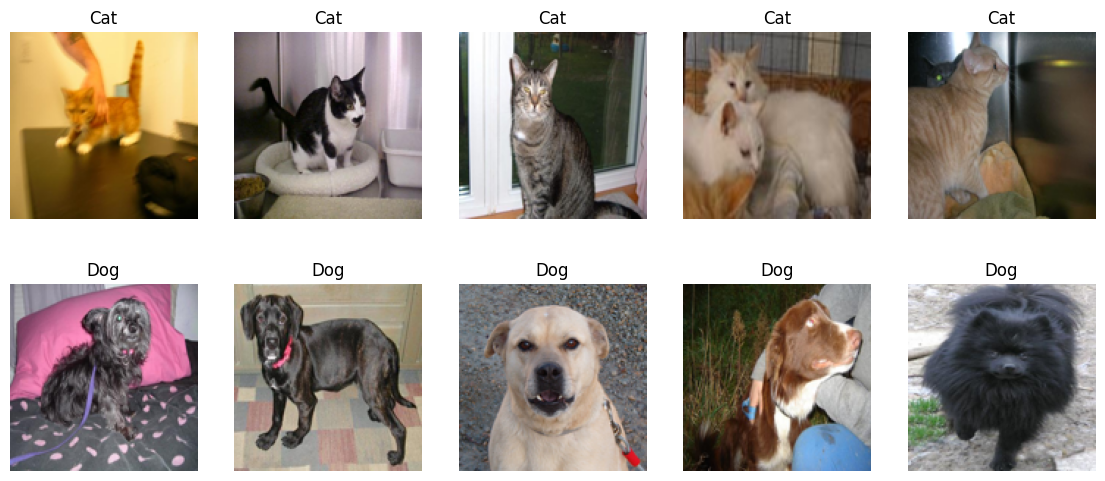

In [7]:
plt.figure(figsize=(14, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i * 300])
    plt.title(class_names[y[i * 300]])
    plt.axis('off')
plt.show()

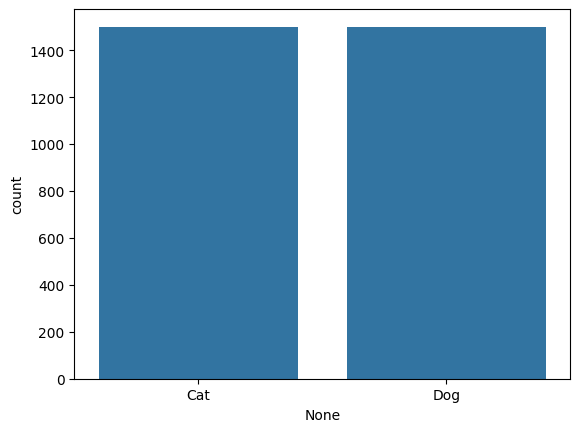

In [8]:
sns.countplot(x=pd.Series(y).map(dict(enumerate(class_names))))
plt.show()

# ***Data Preprocessing***

In [9]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED)
print(X_train.shape, X_val.shape, X_test.shape)

(2100, 128, 128, 3) (450, 128, 128, 3) (450, 128, 128, 3)


# ***Baseline CNN***

In [10]:
baseline_model = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1.0 / 255),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

baseline_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     3,686,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,705,921 (14.14 MB)

 Trainable params: 3,705,921 (14.14 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

baseline_history = baseline_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=32, callbacks=[early_stop], verbose=2)

Epoch 1/30
66/66 - 13s - 191ms/step - accuracy: 0.5310 - loss: 0.7037 - val_accuracy: 0.5778 - val_loss: 0.6916
Epoch 2/30
66/66 - 1s - 17ms/step - accuracy: 0.6505 - loss: 0.6212 - val_accuracy: 0.6733 - val_loss: 0.6302
Epoch 3/30
66/66 - 1s - 17ms/step - accuracy: 0.7371 - loss: 0.5206 - val_accuracy: 0.7067 - val_loss: 0.5851
Epoch 4/30
66/66 - 1s - 17ms/step - accuracy: 0.7995 - loss: 0.4274 - val_accuracy: 0.7022 - val_loss: 0.6249
Epoch 5/30
66/66 - 1s - 17ms/step - accuracy: 0.8667 - loss: 0.3027 - val_accuracy: 0.6711 - val_loss: 0.7532
Epoch 6/30
66/66 - 1s - 17ms/step - accuracy: 0.9038 - loss: 0.2476 - val_accuracy: 0.6578 - val_loss: 0.7685
Epoch 7/30
66/66 - 1s - 17ms/step - accuracy: 0.9048 - loss: 0.2220 - val_accuracy: 0.6511 - val_loss: 0.8154
Epoch 8/30
66/66 - 1s - 19ms/step - accuracy: 0.9252 - loss: 0.1874 - val_accuracy: 0.6756 - val_loss: 1.0114


# ***Improved CNN***

In [12]:
cnn_model = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1.0 / 255),
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),

    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

cnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,705 (16.36 MB)

 Trainable params: 4,288,257 (16.36 MB)

 Non-trainable params: 448 (1.75 KB)

In [13]:
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

cnn_history = cnn_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=50, batch_size=32, callbacks=[early_stop], verbose=2)

Epoch 1/50
66/66 - 11s - 164ms/step - accuracy: 0.5433 - loss: 2.8068 - val_accuracy: 0.4933 - val_loss: 2.2797
Epoch 2/50
66/66 - 3s - 50ms/step - accuracy: 0.5614 - loss: 0.6975 - val_accuracy: 0.5044 - val_loss: 2.2941
Epoch 3/50
66/66 - 3s - 50ms/step - accuracy: 0.5557 - loss: 0.7000 - val_accuracy: 0.5022 - val_loss: 2.6561
Epoch 4/50
66/66 - 3s - 48ms/step - accuracy: 0.5848 - loss: 0.6706 - val_accuracy: 0.5689 - val_loss: 1.0077
Epoch 5/50
66/66 - 5s - 81ms/step - accuracy: 0.5452 - loss: 0.6616 - val_accuracy: 0.5733 - val_loss: 0.7510
Epoch 6/50
66/66 - 3s - 48ms/step - accuracy: 0.6019 - loss: 0.6573 - val_accuracy: 0.5822 - val_loss: 0.8357
Epoch 7/50
66/66 - 3s - 49ms/step - accuracy: 0.6067 - loss: 0.6324 - val_accuracy: 0.6356 - val_loss: 0.7283
Epoch 8/50
66/66 - 4s - 57ms/step - accuracy: 0.6143 - loss: 0.6280 - val_accuracy: 0.6156 - val_loss: 0.8498
Epoch 9/50
66/66 - 3s - 52ms/step - accuracy: 0.6367 - loss: 0.6316 - val_accuracy: 0.6756 - val_loss: 0.7079
Epoch 10

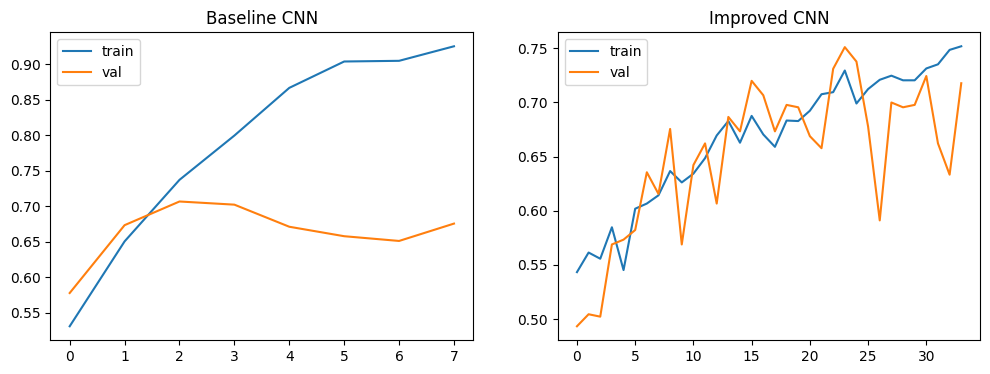

In [14]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(baseline_history.history['accuracy'], label='train')
plt.plot(baseline_history.history['val_accuracy'], label='val')
plt.title('Baseline CNN')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(cnn_history.history['accuracy'], label='train')
plt.plot(cnn_history.history['val_accuracy'], label='val')
plt.title('Improved CNN')
plt.legend()

plt.show()

# ***Evaluating the CNN***

In [15]:
y_prob_cnn = cnn_model.predict(X_test, verbose=0).ravel()
y_pred_cnn = (y_prob_cnn >= 0.5).astype(int)

print(classification_report(y_test, y_pred_cnn, target_names=class_names))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_cnn))

              precision    recall  f1-score   support

         Cat       0.70      0.79      0.74       225
         Dog       0.76      0.66      0.70       225

    accuracy                           0.72       450
   macro avg       0.73      0.72      0.72       450
weighted avg       0.73      0.72      0.72       450

ROC-AUC: 0.786153086419753


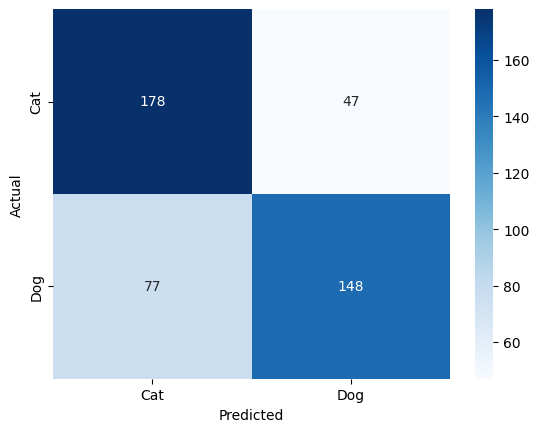

In [16]:
cm = confusion_matrix(y_test, y_pred_cnn)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

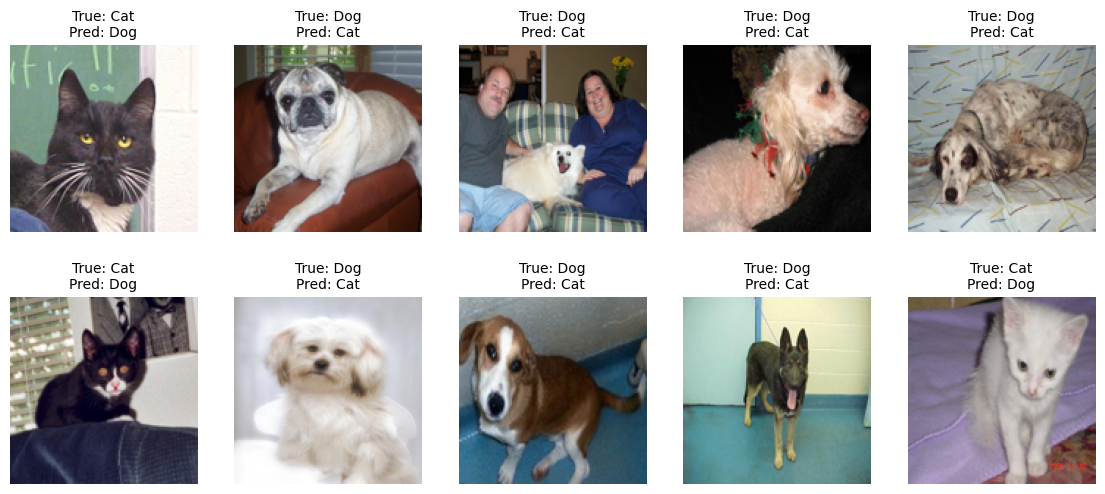

In [17]:
wrong = np.where(y_pred_cnn != y_test)[0]

plt.figure(figsize=(14, 6))
for i, idx in enumerate(wrong[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[idx])
    plt.title(f'True: {class_names[y_test[idx]]}\nPred: {class_names[y_pred_cnn[idx]]}', fontsize=10)
    plt.axis('off')
plt.show()

# ***Baseline vs Improved CNN***

In [18]:
y_prob_base = baseline_model.predict(X_test, verbose=0).ravel()
y_pred_base = (y_prob_base >= 0.5).astype(int)

results = []
for name, y_pred, y_prob in [("Baseline CNN", y_pred_base, y_prob_base), ("Improved CNN", y_pred_cnn, y_prob_cnn)]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Baseline CNN,0.675556,0.685446,0.648889,0.666667,0.735546
1,Improved CNN,0.724444,0.758974,0.657778,0.704762,0.786153


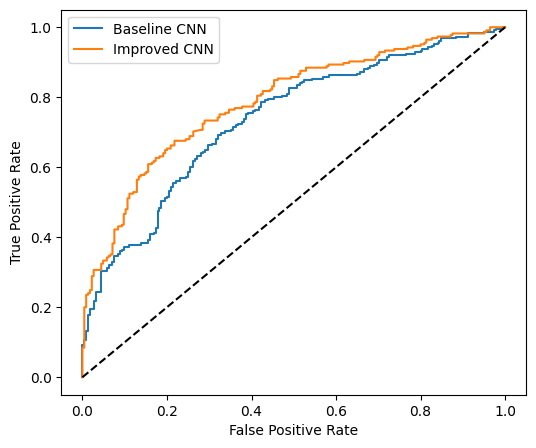

In [19]:
plt.figure(figsize=(6, 5))

for name, y_prob in [("Baseline CNN", y_prob_base), ("Improved CNN", y_prob_cnn)]:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=name)

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

# ***Saving the Model***

In [20]:
cnn_model.save("cats_dogs_cnn.keras")